# Occupational Prestige

How are occupational education scores and prestige associated?

Data: [carData/Duncan](https://vincentarelbundock.github.io/Rdatasets/doc/carData/Duncan.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Occupational aggregates and historical scores cannot represent individual outcomes.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Occupational Prestige',
 'executed_utc': '2026-11-21T10:14:14.327733+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/carData/Duncan.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/carData/Duncan.html',
 'sha256': '120e9430b07ec3e0959cbe19016fce842ff9b2d854b2c1b5b602be4a0bc86ae6',
 'raw_rows': 45,
 'analysis_rows': 45,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8',
 'pearson': 0.8519156284206673,
 'spearman': 0.8393051393952279}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,object,0,0.0,45
1,type,object,0,0.0,3
2,income,int64,0,0.0,30
3,education,int64,0,0.0,36
4,prestige,int64,0,0.0,37


## SQL and analysis
Complete-pair scatter plot of education and prestige, with Pearson and Spearman correlations. No regression adjustment or causal claim.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "education" AS predictor, "prestige" AS outcome FROM observations ORDER BY "education";

Among 45 complete observations, Pearson r = 0.852 and Spearman rho = 0.839.


,predictor,outcome
0,7,15
1,15,13
2,17,3
3,19,10
4,20,24
5,20,8
6,22,26
7,22,16
8,23,33
9,25,29


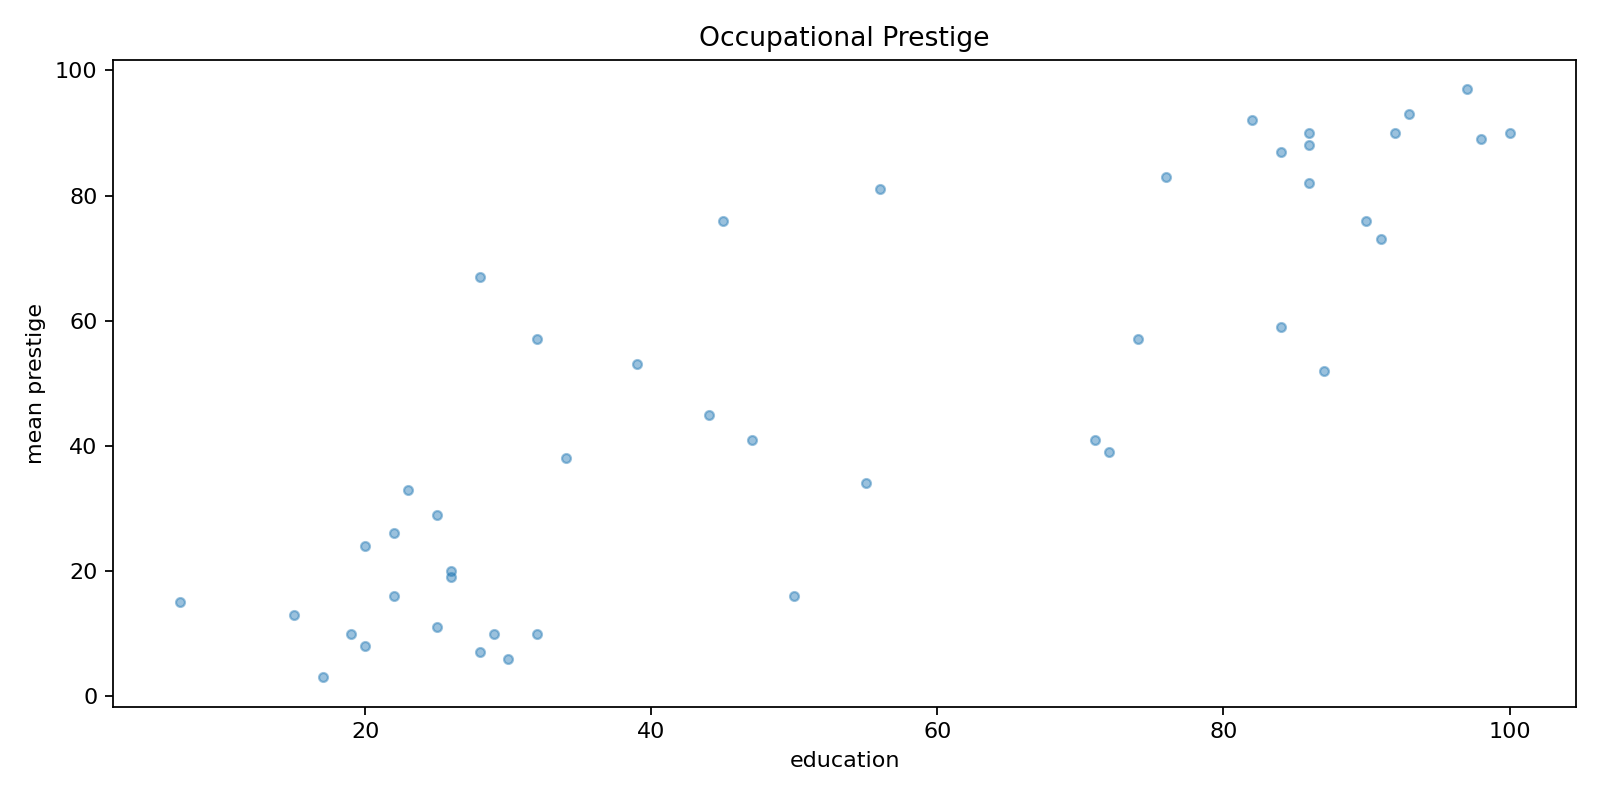

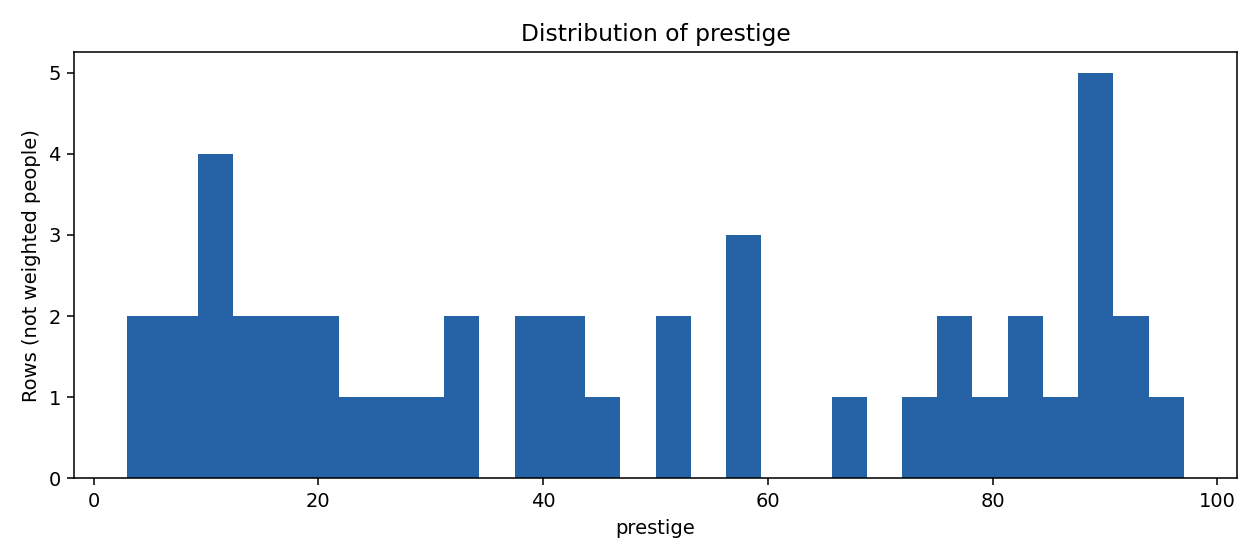

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Occupational aggregates and historical scores cannot represent individual outcomes.

**Next action:** Review source score definitions before interpreting magnitude.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.